# Evolving Quantum Circuits: an interactive walkthrough
**Ben Madan · DCS 340 Project II · Evolutionary Quantum Computation**

This notebook goes with my presentation on
[Bhandari, Nichele, Denysov & Lind (2025), *Optimizing quantum circuits with evolutionary algorithms for stable Boolean gates, elementary cellular automata, and highly entangled quantum states*](https://arxiv.org/abs/2408.00448).
It rebuilds the paper's main ideas from scratch, so you can run them, change them and break them.

**How to use it:** run **Runtime → Run all** once (about 3–4 minutes on the free CPU runtime). Then go back and change the settings in the form cells (the ones with sliders and dropdowns) and re-run just that cell. ✏️ marks the hands-on activities.

| Part | What you'll do |
|---|---|
| 0 | Install dependencies and load the core library |
| 1 | Build a 3-qubit entangled state (GHZ) by hand |
| 2 | Measure entanglement with the Meyer–Wallach (MW) score |
| 3 | Evolve circuits that maximise entanglement |
| 4 | ✏️ Activities A–C: mutation rate, gate pool, gate budget |
| 5 | Investigate the paper's "more gates → less entanglement" result |
| 6 | Task 1: evolve circuits that act like cellular automata, and spot a hidden constraint |
| 7 | Look inside the authors' public code |
| 8 | Wrap-up, discussion questions and references |

> **Why not just run the authors' code?** Their repo ([QUEVO1](https://github.com/shailendrabhandari/QUEVO1), built on [Quevo](https://github.com/Overskott/Quevo)) is written for the pre-1.0 Qiskit API (`from qiskit import Aer, execute`), which current Qiskit no longer supports. So I wrote a small NumPy simulator that is **checked against Qiskit** in Part 1, and we use Qiskit only to draw circuits. We still clone their repo in Part 7 to look at their code.

## Part 0 · Setup
Installs Qiskit (circuit drawing and a cross-check) and `pylatexenc` (needed for Qiskit's matplotlib drawer). NumPy, Matplotlib and ipywidgets are already in Colab.

In [1]:
!pip install -q qiskit pylatexenc ipywidgets
import numpy as np, matplotlib.pyplot as plt, time
import qiskit
from qiskit.quantum_info import Statevector
print("Qiskit", qiskit.__version__, "· NumPy", np.__version__)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"

Qiskit 2.6.1 · NumPy 2.5.4


### The core library
Everything we need is in one cell: a statevector simulator, the gates, the entanglement measures, the EA and the cellular-automaton fitness functions. It's collapsed to keep the notebook readable. Double-click it to read the code. I wrote comments throughout.

**Key conventions**
* A **gene** is `(gate_name, qubits, angle)`, e.g. `("cx", (0, 1), 0.0)` = CNOT with control q0 and target q1. A **chromosome** is a list of genes. This is the same idea as the paper's integer triplets `[gate, target, control]`.
* Qubit 0 is written first (leftmost) in bitstrings like `"011"`.

In [2]:
#@title Core library: simulator, fitness functions, EA (run me)
# ==== Core library: simulator, fitness functions, EA ====
import numpy as np

# ---------- gate definitions ----------
I2 = np.eye(2, dtype=complex)
H_ = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
X_ = np.array([[0, 1], [1, 0]], dtype=complex)
Y_ = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z_ = np.diag([1, -1]).astype(complex)
S_ = np.diag([1, 1j])

def ry(t):
    c, s = np.cos(t / 2), np.sin(t / 2)
    return np.array([[c, -s], [s, c]], dtype=complex)

def controlled(U):
    """2-qubit matrix, qubit order (control, target)."""
    M = np.eye(4, dtype=complex); M[2:, 2:] = U; return M

CX_ = controlled(X_)
CZ_ = controlled(Z_)
SWAP_ = np.array([[1,0,0,0],[0,0,1,0],[0,1,0,0],[0,0,0,1]], dtype=complex)
CCX_ = np.eye(8, dtype=complex); CCX_[6:, 6:] = X_

def rxx(t):
    XX = np.kron(X_, X_); return np.cos(t/2)*np.eye(4) - 1j*np.sin(t/2)*XX
def rzz(t):
    ZZ = np.kron(Z_, Z_); return np.cos(t/2)*np.eye(4) - 1j*np.sin(t/2)*ZZ

# name -> (number of qubits, has an angle?, function(theta) -> matrix)
GATE_LIBRARY = {
    "h":    (1, False, lambda t: H_),
    "x":    (1, False, lambda t: X_),
    "y":    (1, False, lambda t: Y_),
    "z":    (1, False, lambda t: Z_),
    "s":    (1, False, lambda t: S_),
    "ry":   (1, True,  ry),
    "cx":   (2, False, lambda t: CX_),
    "cz":   (2, False, lambda t: CZ_),
    "swap": (2, False, lambda t: SWAP_),
    "rxx":  (2, True,  rxx),
    "rzz":  (2, True,  rzz),
    "ccx":  (3, False, lambda t: CCX_),
}

# ---------- statevector simulator ----------
def apply_gate(psi, U, qubits, n):
    """Apply a k-qubit matrix U to the listed qubits of an n-qubit state (qubit 0 = first tensor axis)."""
    k = len(qubits)
    shape = psi.shape                      # (2**n,) or (2**n, batch)
    psi = psi.reshape([2] * n + [-1])      # trailing axis = batch of states
    U = U.reshape([2] * (2 * k))
    psi = np.tensordot(U, psi, axes=(list(range(k, 2 * k)), list(qubits)))
    psi = np.moveaxis(psi, list(range(k)), list(qubits))
    return psi.reshape(shape)

def basis_state(bits):
    n = len(bits); psi = np.zeros(2 ** n, dtype=complex)
    psi[int("".join(str(b) for b in bits), 2)] = 1; return psi

def simulate(chrom, n, psi=None):
    """chrom = list of genes (gate_name, qubits_tuple, theta)."""
    if psi is None:
        psi = basis_state([0] * n)
    for name, qubits, theta in chrom:
        U = GATE_LIBRARY[name][2](theta)
        psi = apply_gate(psi, U, qubits, n)
    return psi

def probabilities(psi, n):
    return {format(i, f"0{n}b"): float(abs(a) ** 2) for i, a in enumerate(psi) if abs(a) ** 2 > 1e-9}

# ---------- entanglement measures ----------
def reduced_density_matrix(psi, n, k):
    """Single-qubit reduced density matrix rho_k (trace out every other qubit)."""
    m = np.moveaxis(psi.reshape([2] * n), k, 0).reshape(2, -1)
    return m @ m.conj().T

def purity(rho):
    return float(np.real(np.trace(rho @ rho)))

def meyer_wallach(psi, n):
    """Q = 2 * (1 - mean_k Tr[rho_k^2]); 0 = product state, 1 = maximal (paper Eq. 9)."""
    return 2 * (1 - np.mean([purity(reduced_density_matrix(psi, n, k)) for k in range(n)]))

def von_neumann_entropy(rho):
    ev = np.linalg.eigvalsh(rho); ev = ev[ev > 1e-12]
    return float(-np.sum(ev * np.log2(ev)))

# ---------- the evolutionary algorithm ----------
def random_gene(n, pool, rng):
    name = pool[rng.integers(len(pool))]
    k, has_angle, _ = GATE_LIBRARY[name]
    if k > n:  # e.g. ccx on 2 qubits: fall back to a 1-qubit gate
        return random_gene(n, [g for g in pool if GATE_LIBRARY[g][0] <= n], rng)
    qubits = tuple(int(q) for q in rng.choice(n, size=k, replace=False))  # always distinct = valid
    theta = float(rng.uniform(0, 2 * np.pi)) if has_angle else 0.0
    return (name, qubits, theta)

def random_chromosome(n, n_gates, pool, rng):
    return [random_gene(n, pool, rng) for _ in range(n_gates)]

def mutate(chrom, n, pool, rate, rng):
    """Each gene is replaced by a fresh random gene with probability `rate`."""
    return [random_gene(n, pool, rng) if rng.random() < rate else g for g in chrom]

def evolve(fitness_fn, n, n_gates, pool, mutation_rate=0.10, pop_size=20, generations=200,
           n_elites=4, maximize=True, seed=None, init=None):
    """Mutation-only EA with elitism, like the paper.
    Returns dict with best/mean fitness per generation and the best chromosome."""
    rng = np.random.default_rng(seed)
    pop = init or [random_chromosome(n, n_gates, pool, rng) for _ in range(pop_size)]
    sign = 1 if maximize else -1
    best_hist, mean_hist = [], []
    for _ in range(generations):
        fit = np.array([fitness_fn(c) for c in pop])
        order = np.argsort(-sign * fit)
        best_hist.append(fit[order[0]]); mean_hist.append(fit.mean())
        elites = [pop[i] for i in order[:n_elites]]
        # fitness-proportionate choice of parents (on a "higher is better" scale)
        score = sign * fit; score = score - score.min() + 1e-9
        probs = score / score.sum()
        children = []
        while len(elites) + len(children) < pop_size:
            parent = pop[rng.choice(pop_size, p=probs)]
            children.append(mutate(parent, n, pool, mutation_rate, rng))
        pop = elites + children
    fit = np.array([fitness_fn(c) for c in pop]); b = int(np.argmax(sign * fit))
    return {"best": np.array(best_hist), "mean": np.array(mean_hist), "best_chrom": pop[b], "best_fit": float(fit[b])}

def run_many(fitness_fn, runs=10, **kw):
    """Run the EA several times with different seeds; return stacked histories."""
    results = [evolve(fitness_fn, seed=s, **kw) for s in range(runs)]
    return {"best": np.array([r["best"] for r in results]),
            "mean": np.array([r["mean"] for r in results]),
            "results": results}

# ---------- Task 1: cellular automata ----------
NEIGHBORHOODS = [(0,0,0),(0,0,1),(0,1,0),(0,1,1),(1,0,0),(1,0,1),(1,1,0),(1,1,1)]
CA_TARGETS = {  # P(new centre cell = 1) for each neighbourhood, from Table 1 of the paper
    "Rule 90":       [0, 1, 0, 1, 1, 0, 1, 0],
    "Rule 110":      [0, 1, 1, 1, 0, 1, 1, 0],
    "Critical CA":   [0.394221, 0.094721, 0.239492, 0.408455, 0, 0.730203, 0.915034, 1],
    "Random 3":      [0.1988, 0.4701, 0.9836, 0.7115, 0.6616, 0.1218, 0.1328, 0.7306],
}

ALL_INPUTS_3 = np.eye(8, dtype=complex)   # column j = basis state |j>, i.e. neighbourhood NEIGHBORHOODS[j]

def ca_outputs(chrom):
    """For each of the 8 neighbourhoods: prepare |abc>, run the circuit, return P(q0 = 1).
    All 8 inputs are simulated at once as a batch."""
    out = simulate(chrom, 3, ALL_INPUTS_3.copy())          # shape (8 amplitudes, 8 inputs)
    return np.sum(np.abs(out[4:, :]) ** 2, axis=0)         # amplitudes with q0 = 1 are rows 4..7

def kl_bernoulli(chrom, target, eps=1e-6):
    """Strict version: sum over the 8 neighbourhoods of KL(target_i || circuit_i) for each coin flip.
    0 only if every probability matches exactly."""
    p = np.clip(np.array(target, float), eps, 1 - eps)
    q = np.clip(ca_outputs(chrom), eps, 1 - eps)
    return float(np.sum(p * np.log(p / q) + (1 - p) * np.log((1 - p) / (1 - q))))

def kl_normalized(chrom, target, eps=1e-6):
    """Paper-style version (Eq. 1): treat the 8 values as ONE distribution by normalising both,
    then D_KL(P || Q). Only the *shape* has to match, not the actual probabilities."""
    p = np.array(target, float) + eps; p = p / p.sum()
    q = ca_outputs(chrom) + eps;       q = q / q.sum()
    return float(np.sum(p * np.log(p / q)))

# ---------- convert to Qiskit (for drawing / cross-checking) ----------
def to_qiskit(chrom, n):
    from qiskit import QuantumCircuit
    qc = QuantumCircuit(n)
    for name, q, t in chrom:
        if name == "ry": qc.ry(t, q[0])
        elif name in ("rxx", "rzz"): getattr(qc, name)(t, q[0], q[1])
        elif name == "ccx": qc.ccx(q[0], q[1], q[2])
        else: getattr(qc, name)(*q)
    return qc

In [3]:
#@title Plotting helpers (run me)
def plot_runs(stats, label="", color=BLUE, ax=None, show_mean=True):
    ax = ax or plt.gca()
    g = np.arange(stats["best"].shape[1])
    b = stats["best"].mean(0); be = stats["best"].std(0) / np.sqrt(len(stats["best"]))
    ax.plot(g, b, color=color, lw=2, label=f"{label} best".strip())
    ax.fill_between(g, b - be, b + be, color=color, alpha=0.15)
    if show_mean:
        ax.plot(g, stats["mean"].mean(0), color=color, lw=1.2, ls="--", label=f"{label} population average".strip())
    ax.set_xlabel("generation")
    return ax

def show_circuit(chrom, n, title=None):
    fig = to_qiskit(chrom, n).draw("mpl", fold=-1)
    if title: fig.suptitle(title)
    display(fig); plt.close(fig)

def bar_probs(psi, n, title=""):
    pr = {format(i, f"0{n}b"): abs(a)**2 for i, a in enumerate(psi)}
    plt.figure(figsize=(6, 2.6)); plt.bar(pr.keys(), pr.values(), color=BLUE)
    plt.ylabel("probability"); plt.title(title); plt.ylim(0, 1); plt.xticks(rotation=45); plt.show()

## Part 1 · Qubits, gates and the GHZ state
A qubit's state is a list of complex **amplitudes**, one per bitstring. The chance of measuring a bitstring is its amplitude squared. Three qubits give 2³ = 8 amplitudes.

Two gates do most of the work:
* **H (Hadamard)** turns a definite `0` into a 50/50 superposition of 0 and 1.
* **CNOT (`cx`)** flips the *target* qubit only when the *control* qubit is 1.

**H on q0, then CNOT q0→q1, then CNOT q1→q2** gives the GHZ state (|000⟩ + |111⟩)/√2. All three qubits are measured as 0 together or 1 together, never a mix. That's entanglement.

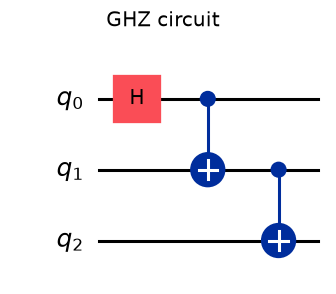

non-zero probabilities: {'000': 0.4999999999999999, '111': 0.4999999999999999}


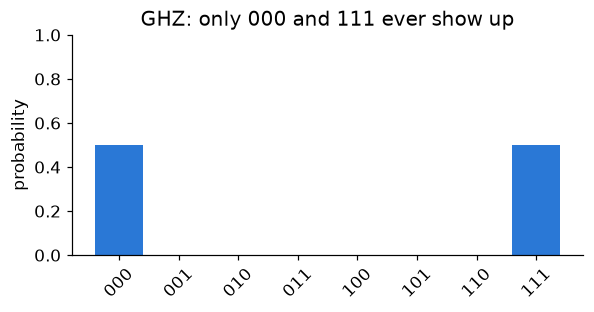

In [4]:
ghz = [("h", (0,), 0.0), ("cx", (0, 1), 0.0), ("cx", (1, 2), 0.0)]
show_circuit(ghz, 3, "GHZ circuit")
psi = simulate(ghz, 3)
print("non-zero probabilities:", probabilities(psi, 3))
bar_probs(psi, 3, "GHZ: only 000 and 111 ever show up")

**Sanity check:** does my simulator agree with Qiskit? Below, 200 random circuits using *every* gate in the library are run through both.

In [5]:
rng = np.random.default_rng(0)
worst = 0
for _ in range(200):
    n = int(rng.integers(2, 6)); c = random_chromosome(n, 12, list(GATE_LIBRARY), rng)
    ours = simulate(c, n)
    theirs = Statevector(to_qiskit(c, n)).reverse_qargs().data   # Qiskit orders qubits the other way round
    worst = max(worst, np.abs(ours - theirs).max())
print(f"largest difference from Qiskit over 200 random circuits: {worst:.1e}")

largest difference from Qiskit over 200 random circuits: 1.1e-16


## Part 2 · Putting a number on entanglement: Meyer–Wallach
The paper's fitness for Task 2 is the **Meyer–Wallach (MW) measure** (paper Eq. 9):

$$Q(|\psi\rangle) = 2\Big(1 - \frac{1}{n}\sum_{k} \mathrm{Tr}[\rho_k^2]\Big)$$

In plain words:
1. **Look at one qubit alone.** "Trace out" all the others to get its reduced density matrix $\rho_k$, a 2×2 matrix.
2. **Check its purity** $\mathrm{Tr}[\rho_k^2]$. It is **1** if the qubit is in a definite state on its own, and **½** if it looks like a perfect coin flip. A qubit that's part of a pure state only looks like a coin flip when it is entangled with the rest.
3. **Average over the qubits** and rescale, so the score runs from **0** (no entanglement) to **1** (maximal).

In [6]:
def state_from(chrom, n): return simulate(chrom, n)
examples = {
    "product |000>":          ([], 3),
    "superposition, no CNOT": ([("h",(0,),0),("h",(1,),0),("h",(2,),0)], 3),
    "Bell pair + free qubit": ([("h",(0,),0),("cx",(0,1),0)], 3),
    "GHZ (3 qubits)":         (ghz, 3),
    "GHZ (5 qubits)":         ([("h",(0,),0)] + [("cx",(i,i+1),0) for i in range(4)], 5),
}
print(f"{'state':26s} {'per-qubit purity':28s} MW")
for name, (c, n) in examples.items():
    psi = state_from(c, n)
    pur = [round(purity(reduced_density_matrix(psi, n, k)), 2) for k in range(n)]
    print(f"{name:26s} {str(pur):28s} {meyer_wallach(psi, n):.3f}")

state                      per-qubit purity             MW
product |000>              [1.0, 1.0, 1.0]              0.000
superposition, no CNOT     [1.0, 1.0, 1.0]              0.000
Bell pair + free qubit     [0.5, 0.5, 1.0]              0.667
GHZ (3 qubits)             [0.5, 0.5, 0.5]              1.000
GHZ (5 qubits)             [0.5, 0.5, 0.5, 0.5, 0.5]    1.000


Notice that **superposition is not entanglement**: three H gates give every bitstring equal odds but MW = 0, because each qubit is still independent.

✏️ **Try it:** below, q0 first gets a rotation $R_Y(\theta)$, then the two CNOTs. At θ = 0 nothing is entangled, and at θ = π/2 it's exactly the GHZ state. Drag the slider and watch MW change smoothly.

In [7]:
import ipywidgets as widgets
thetas = np.linspace(0, np.pi, 181)
curve = [meyer_wallach(simulate([("ry",(0,),t),("cx",(0,1),0),("cx",(1,2),0)], 3), 3) for t in thetas]
def explore(theta=0.6):
    c = [("ry",(0,),theta),("cx",(0,1),0),("cx",(1,2),0)]
    psi = simulate(c, 3); q = meyer_wallach(psi, 3)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot(thetas, curve, color=BLUE); ax[0].axvline(theta, color=ORANGE)
    ax[0].set_xlabel("θ (radians)"); ax[0].set_ylabel("MW"); ax[0].set_title(f"MW = {q:.3f}")
    pr = {format(i,"03b"): abs(a)**2 for i,a in enumerate(psi)}
    ax[1].bar(pr.keys(), pr.values(), color=BLUE); ax[1].set_ylim(0,1); ax[1].set_title("measurement probabilities")
    plt.tight_layout(); plt.show()
widgets.interact(explore, theta=widgets.FloatSlider(min=0, max=np.pi, step=0.02, value=0.6, description="θ"));

interactive(children=(FloatSlider(value=0.6, description='θ', max=3.141592653589793, step=0.02), Output()), _d…

## Part 3 · Letting evolution design the circuit
Now we stop designing by hand. The EA follows the paper (Sec. 2.1 and Supplementary Note I):

1. **Population:** 20 random chromosomes (circuits).
2. **Simulate and score** each circuit with MW.
3. **Elitism:** the best 4 are copied into the next generation unchanged.
4. **Mutation:** the other 16 are copies of parents chosen by fitness, and each gene is swapped for a random new gene with probability `mutation_rate`.
5. Repeat. There's **no crossover**, the same as the paper.

The settings below are a form. Change them and re-run the cell.

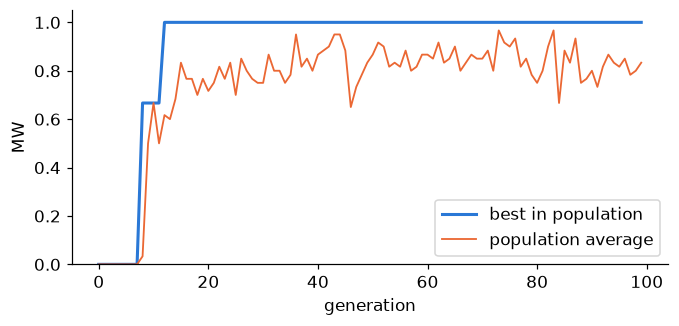

best MW found: 1.0000


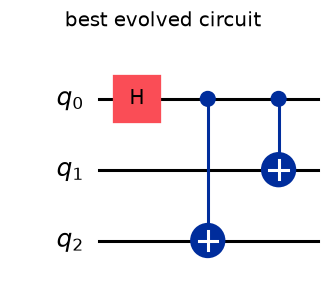

its measurement probabilities: {'000': 0.4999999999999999, '111': 0.4999999999999999}


In [8]:
#@title Evolve one entangling circuit { run: "auto" }
n_qubits = 3        #@param {type:"slider", min:2, max:6, step:1}
n_gates = 3         #@param {type:"slider", min:1, max:20, step:1}
mutation_rate = 0.1 #@param {type:"slider", min:0, max:1, step:0.01}
generations = 100   #@param {type:"slider", min:10, max:500, step:10}
seed = 0            #@param {type:"integer"}
pool = ["h", "x", "s", "cx", "cz"]

fitness = lambda c: meyer_wallach(simulate(c, n_qubits), n_qubits)
res = evolve(fitness, n=n_qubits, n_gates=n_gates, pool=pool, mutation_rate=mutation_rate,
             generations=generations, seed=seed)
plt.figure(figsize=(7, 3))
plt.plot(res["best"], color=BLUE, lw=2, label="best in population")
plt.plot(res["mean"], color=ORANGE, lw=1.2, label="population average")
plt.ylim(0, 1.05); plt.xlabel("generation"); plt.ylabel("MW"); plt.legend(); plt.show()
print(f"best MW found: {res['best_fit']:.4f}")
show_circuit(res["best_chrom"], n_qubits, "best evolved circuit")
print("its measurement probabilities:", probabilities(simulate(res["best_chrom"], n_qubits), n_qubits))

With the defaults (3 qubits, 3 gates), evolution usually rediscovers the **GHZ circuit from Part 1**: one H and two CNOTs, with MW = 1. Nobody told it that circuit exists.

## Part 4 · ✏️ Hands-on activities
For each activity, **write down your prediction first**, then run the cell. The interesting part is when you're wrong.

### Activity A: mutation rate
The paper found that higher mutation lowered the *average* fitness but not the *best*. Try extreme values: 0 (no mutation at all) and 0.8.
> 🔮 Prediction: what happens to the best and the average at 0? At 0.8?

rate  0.0: final best 0.625 | population average 0.625


rate 0.05: final best 1.000 | population average 0.897


rate  0.2: final best 1.000 | population average 0.630


rate  0.8: final best 1.000 | population average 0.315


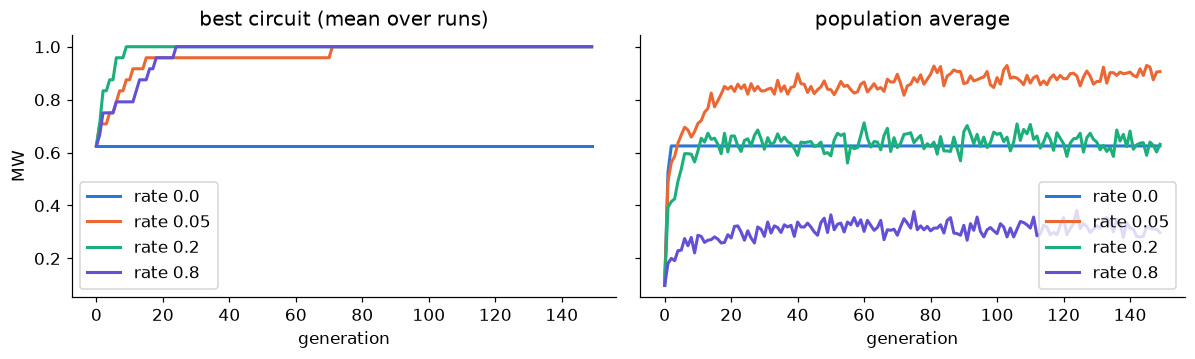

In [9]:
#@title Activity A: compare mutation rates
rates = "0.0, 0.05, 0.2, 0.8"  #@param {type:"string"}
n_qubits = 4  #@param {type:"slider", min:2, max:6, step:1}
n_gates = 8   #@param {type:"slider", min:1, max:20, step:1}
runs = 6      #@param {type:"slider", min:2, max:20, step:1}
rate_list = [float(r) for r in rates.split(",")]
fit = lambda c: meyer_wallach(simulate(c, n_qubits), n_qubits)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
cols = [BLUE, ORANGE, AQUA, VIOLET, "#e34948", "#008300"]
for r, col in zip(rate_list, cols):
    s = run_many(fit, runs=runs, n=n_qubits, n_gates=n_gates, pool=["h","x","s","cx","cz"], mutation_rate=r, generations=150)
    ax[0].plot(s["best"].mean(0), color=col, lw=2, label=f"rate {r}")
    ax[1].plot(s["mean"].mean(0), color=col, lw=2, label=f"rate {r}")
    print(f"rate {r:>4}: final best {s['best'][:,-1].mean():.3f} | population average {s['mean'][:,-20:].mean():.3f}")
ax[0].set_title("best circuit (mean over runs)"); ax[1].set_title("population average")
for a in ax: a.set_xlabel("generation"); a.legend()
ax[0].set_ylabel("MW"); plt.tight_layout(); plt.show()

<details><summary>💡 What's going on? (open after predicting)</summary>

* **Rate 0:** children are exact copies, so the EA can never improve on the best *random* starting circuit.
* **High rates:** most children are scrambled, so the average drops. **Elitism** still protects the best 4, so the best curve barely suffers. That's why the paper says mutation rate mostly affects the average.
</details>

### Activity B: what if the gate pool can't express the answer?
Untick the two-qubit gates (`cx`, `cz`).
> 🔮 Prediction: what's the best MW evolution can reach now?

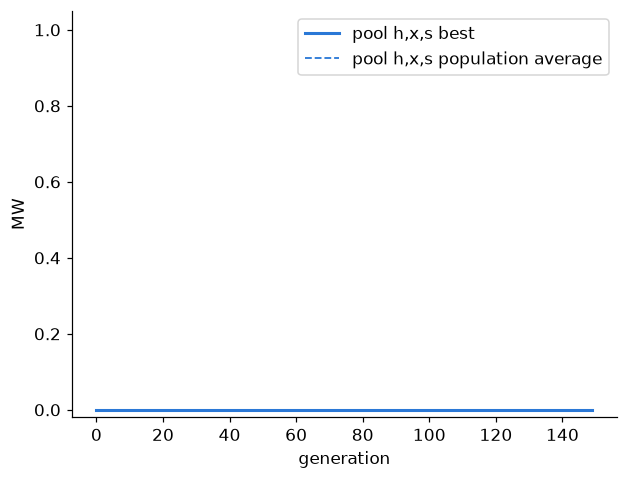

gate pool: ['h', 'x', 's'] → best MW across runs: 0.0


In [10]:
#@title Activity B: choose the gate pool
use_h = True   #@param {type:"boolean"}
use_x = True   #@param {type:"boolean"}
use_s = True   #@param {type:"boolean"}
use_ry = False #@param {type:"boolean"}
use_cx = False #@param {type:"boolean"}
use_cz = False #@param {type:"boolean"}
pool_b = [g for g, on in [("h",use_h),("x",use_x),("s",use_s),("ry",use_ry),("cx",use_cx),("cz",use_cz)] if on]
fit = lambda c: meyer_wallach(simulate(c, 3), 3)
s = run_many(fit, runs=5, n=3, n_gates=6, pool=pool_b, generations=150)
plot_runs(s, "pool " + ",".join(pool_b)); plt.ylim(-0.02, 1.05); plt.ylabel("MW"); plt.legend(); plt.show()
print("gate pool:", pool_b, "→ best MW across runs:", round(s["best"][:, -1].max(), 4))

<details><summary>💡 What's going on?</summary>

Without a two-qubit gate the best is **exactly 0**, however long you evolve. Single-qubit gates act on each qubit separately, so they can never link qubits together. **An EA can only find what the representation can express.** That's a general lesson about choosing a genome, not only a quantum one.
</details>

### Activity C: gate budget
5 qubits, but only 3 gates.
> 🔮 Prediction: will it reach MW = 1? What's the *fewest* gates that can?

 3 gates → mean best MW 0.600


 4 gates → mean best MW 0.800


 5 gates → mean best MW 0.920


 8 gates → mean best MW 1.000


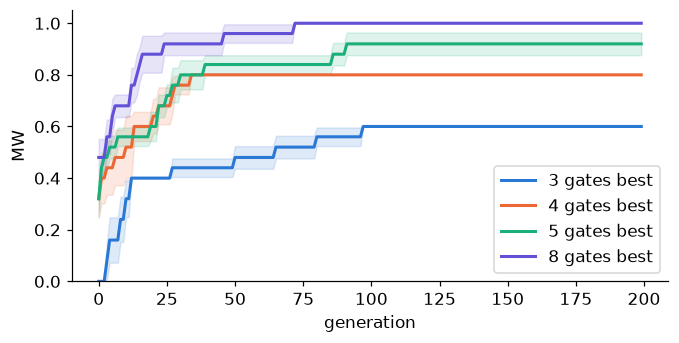

In [11]:
#@title Activity C: gates vs. qubits
n_qubits = 5            #@param {type:"slider", min:2, max:6, step:1}
gate_counts = "3, 4, 5, 8" #@param {type:"string"}
fit = lambda c: meyer_wallach(simulate(c, n_qubits), n_qubits)
plt.figure(figsize=(7, 3.2))
for g, col in zip([int(x) for x in gate_counts.split(",")], [BLUE, ORANGE, AQUA, VIOLET, "#e34948"]):
    s = run_many(fit, runs=5, n=n_qubits, n_gates=g, pool=["h","x","s","cx","cz"], generations=200)
    plot_runs(s, f"{g} gates", col, show_mean=False)
    print(f"{g:2d} gates → mean best MW {s['best'][:,-1].mean():.3f}")
plt.ylim(0, 1.05); plt.ylabel("MW"); plt.legend(); plt.show()

<details><summary>💡 What's going on?</summary>

To entangle *every* qubit, the two-qubit gates have to connect all 5 qubits, which takes at least **4** of them. You also need one H to create a superposition, so the minimum is **5 gates** (for example, H plus a chain of 4 CNOTs). With fewer gates some qubits are always left out, and the score stalls below 1.
</details>

## Part 5 · Investigating: does adding gates really *hurt* entanglement?
The paper reports that a **5-qubit circuit with 12 gates scored 0.199**, against 0.999 with 5 gates, and concludes that entanglement capability drops as circuits get more complex (Sec. 3.2.2 and the Discussion).

This seemed odd to me. A 12-gate circuit can do anything a 5-gate circuit can, because extra gates can undo each other. If the score is lower, I'd expect the cause to be the **search** (more genes to get right), not the **circuit**.

So I tested it with two gate pools:
* **simple:** H, X, S, CX, CZ
* **paper-style:** the gates listed in the authors' code (`cx, x, z, y, h, rxx, rzz, swap, toffoli`), including rotations with random angles

simple        5 gates → best MW per run: [1.  1.  0.8 0.8 1.  1. ]


simple       12 gates → best MW per run: [1. 1. 1. 1. 1. 1.]


paper-style   5 gates → best MW per run: [0.987 0.999 0.998 0.994 0.985 1.   ]


paper-style  12 gates → best MW per run: [1. 1. 1. 1. 1. 1.]


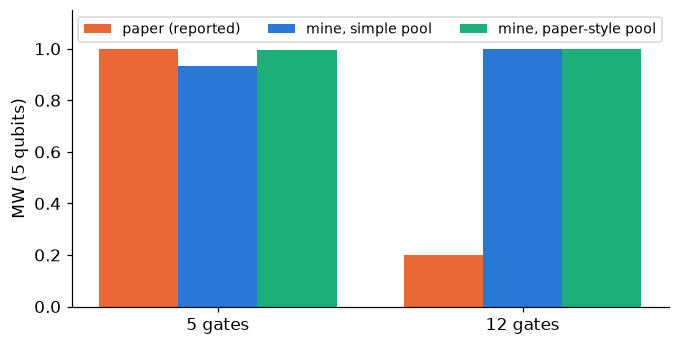

In [12]:
#@title Run the comparison (≈1 minute)
runs = 6 #@param {type:"slider", min:2, max:20, step:1}
pools = {"simple": ["h","x","s","cx","cz"], "paper-style": ["cx","x","z","y","h","rxx","rzz","swap","ccx"]}
fit5 = lambda c: meyer_wallach(simulate(c, 5), 5)
table = {}
for pname, p in pools.items():
    for g in (5, 12):
        s = run_many(fit5, runs=runs, n=5, n_gates=g, pool=p, generations=200)
        table[(pname, g)] = s["best"][:, -1]
        print(f"{pname:12s} {g:2d} gates → best MW per run: {np.round(s['best'][:,-1], 3)}")
labels = ["5 gates", "12 gates"]; x = np.arange(2); w = 0.26
plt.figure(figsize=(7, 3.5))
plt.bar(x - w, [0.999, 0.199], w, color=ORANGE, label="paper (reported)")
plt.bar(x,      [table[("simple", g)].mean() for g in (5, 12)], w, color=BLUE, label="mine, simple pool")
plt.bar(x + w,  [table[("paper-style", g)].mean() for g in (5, 12)], w, color=AQUA, label="mine, paper-style pool")
plt.xticks(x, labels); plt.ylabel("MW (5 qubits)"); plt.ylim(0, 1.15); plt.legend(ncol=3, fontsize=9); plt.show()

**What I found:** with either gate pool, 12 gates reach MW ≈ 1 in every run. I couldn't reproduce the drop to 0.199. Possible explanations, worth discussing:
* their run had a different setup (fewer generations, a different fitness implementation; see Part 7),
* that particular run simply got stuck, since a single run is a small sample,
* or something about their code that I haven't copied.

Either way, "the EA didn't find it" and "the circuit can't do it" are different claims, and the data only supports the first.

## Part 6 · Task 1: circuits that behave like cellular automata
An **elementary cellular automaton** updates each cell from its 3-cell neighbourhood (left, centre, right), so a rule is just 8 output values. A **stochastic** CA gives a *probability* of becoming 1 instead.

**The quantum version** (paper Sec. 3.1): 3 qubits hold the neighbourhood. For each of the 8 neighbourhoods, prepare that basis state, run the circuit and measure **q0**. The probability of reading 1 should match the rule. The fitness is a **KL divergence** between the targets and the circuit's outputs, where **0 = perfect** (so here we *minimise*).

Targets from the paper's Table 1:

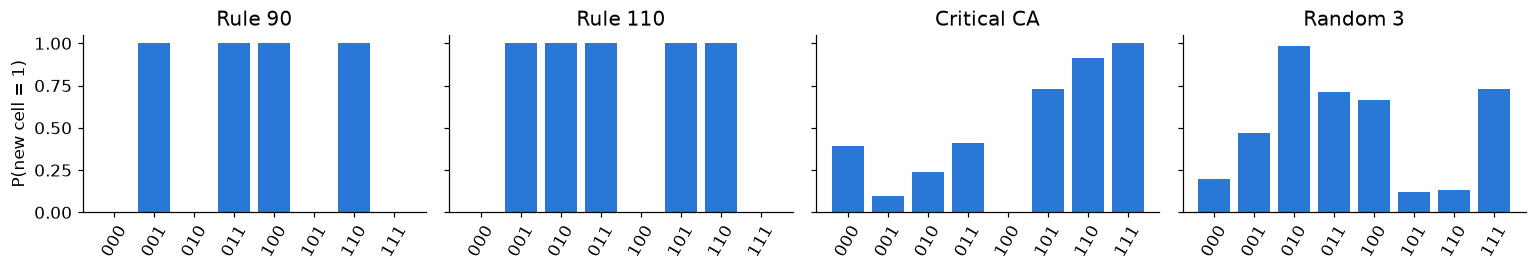

In [13]:
fig, ax = plt.subplots(1, len(CA_TARGETS), figsize=(14, 2.6), sharey=True)
for a, (name, t) in zip(ax, CA_TARGETS.items()):
    a.bar(["".join(map(str, nb)) for nb in NEIGHBORHOODS], t, color=BLUE); a.set_title(name)
    a.tick_params(axis="x", rotation=60)
ax[0].set_ylabel("P(new cell = 1)"); plt.tight_layout(); plt.show()

### A hidden constraint I found
While testing this, I noticed something that isn't in the paper. Add up P(q0 = 1) over the 8 inputs for **any** 3-qubit circuit and you always get exactly **4**.

Why: the 8 inputs form a complete basis, and the sum works out to $\mathrm{Tr}[U^\dagger P_1 U] = \mathrm{Tr}[P_1] = 4$, where $P_1$ projects onto "q0 = 1". Half of the space has q0 = 1, whatever $U$ does.

So a CA target whose 8 values don't sum to 4 **can't be matched exactly by any circuit**. Check the sums:

In [14]:
rng = np.random.default_rng(1)
print("Sum of P(q0=1) over the 8 inputs, for 5 random circuits:",
      [round(ca_outputs(random_chromosome(3, 15, ["x","h","cx","ccx","ry"], rng)).sum(), 6) for _ in range(5)])
for name, t in CA_TARGETS.items():
    print(f"{name:12s} target sum = {sum(t):.3f}  →  {'reachable' if abs(sum(t)-4) < 0.02 else 'NOT exactly reachable'}")

Sum of P(q0=1) over the 8 inputs, for 5 random circuits: [np.float64(4.0), np.float64(4.0), np.float64(4.0), np.float64(4.0), np.float64(4.0)]
Rule 90      target sum = 4.000  →  reachable
Rule 110     target sum = 5.000  →  NOT exactly reachable
Critical CA  target sum = 3.782  →  NOT exactly reachable
Random 3     target sum = 4.011  →  reachable


Rule 110 has five 1s, so it's impossible to match exactly. Yet the paper reports Rule 110 with KL ≈ 0. How?

The paper's Eq. 1 treats the 8 values as **one probability distribution**. If both sides are normalised, only the **shape** has to match. A circuit that outputs 0.8 where Rule 110 says 1 has the same shape, so it scores ≈ 0.

Below, the same EA runs with two fitness functions:
* `kl_normalized`: the paper-style version, normalised
* `kl_bernoulli`: a strict version that compares each of the 8 probabilities directly

kl_normalized  best KL 0.0070 | circuit outputs [0.   0.75 1.   0.75 0.   0.75 0.75 0.  ]


kl_bernoulli   best KL 1.3564 | circuit outputs [0.08 0.92 0.65 0.92 0.   0.76 0.67 0.  ]


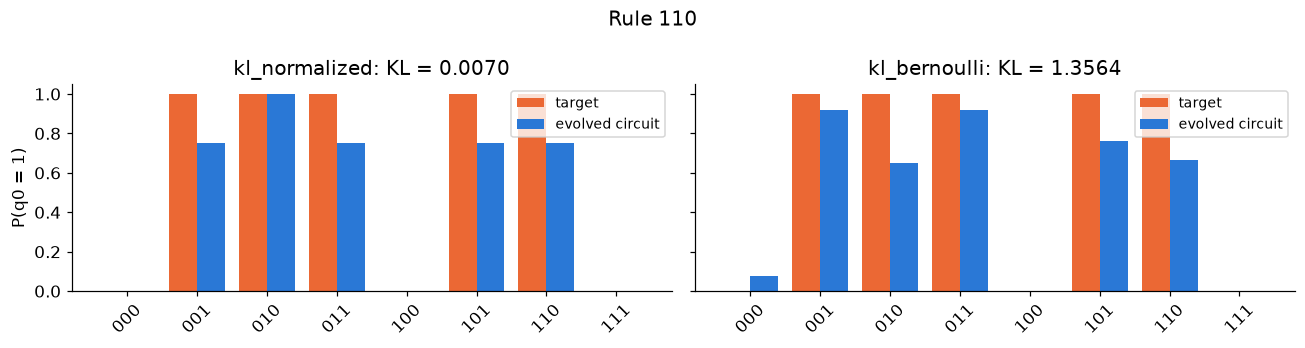

In [15]:
#@title Evolve a CA circuit with both fitness functions (≈20 s)
rule = "Rule 110" #@param ["Rule 90", "Rule 110", "Critical CA", "Random 3"]
n_gates = 15      #@param {type:"slider", min:3, max:25, step:1}
runs = 4          #@param {type:"slider", min:1, max:10, step:1}
ca_pool = ["x", "h", "cx", "ccx", "ry"]
target = CA_TARGETS[rule]; labels = ["".join(map(str, nb)) for nb in NEIGHBORHOODS]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for a, fn in zip(ax, [kl_normalized, kl_bernoulli]):
    s = run_many(lambda c: fn(c, target), runs=runs, n=3, n_gates=n_gates, pool=ca_pool, generations=300, maximize=False)
    best = s["results"][int(np.argmin(s["best"][:, -1]))]
    out = ca_outputs(best["best_chrom"])
    x = np.arange(8)
    a.bar(x - 0.2, target, 0.4, color=ORANGE, label="target")
    a.bar(x + 0.2, out, 0.4, color=BLUE, label="evolved circuit")
    a.set_xticks(x, labels, rotation=45); a.set_title(f"{fn.__name__}: KL = {best['best_fit']:.4f}"); a.legend(fontsize=9)
    print(f"{fn.__name__:14s} best KL {best['best_fit']:.4f} | circuit outputs {np.round(out, 2)}")
ax[0].set_ylabel("P(q0 = 1)"); plt.suptitle(rule); plt.tight_layout(); plt.show()

With **Rule 110**, the normalised score is close to 0, yet the circuit fires only about 75% of the time where the rule says 100%. The strict score exposes that.

**The lesson:** a fitness function can reward something different from what you meant. The EA optimises exactly what you wrote down, and nothing more. (This also probably explains why Rule 90 and "Random 3", whose sums are ≈ 4, scored best in the paper's Fig. 4.)

## Part 7 · Looking inside the authors' public code
Reading code is part of reading a paper. Let's clone the authors' repository and look at their MW function.

In [16]:
!git clone -q --depth 1 https://github.com/shailendrabhandari/QUEVO1.git 2>/dev/null || echo "already cloned"
!sed -n '/def partial_trace/,/return entanglement/p' QUEVO1/QUEVO/Circuit.py

    def partial_trace(self, matrix, keep):
        matrix = np.asarray(matrix)
        keep_indices = list(range(0, len(keep)))

        trace_over_indices = [i for i in range(self.n_qubits) if i not in keep_indices]

        reshaped_dimensions = [2] * self.n_qubits * 2
        matrix = matrix.reshape(reshaped_dimensions)

        for index in sorted(trace_over_indices, reverse=True):
            axis2 = index + len(trace_over_indices)
            matrix = np.trace(matrix, axis1=index, axis2=axis2)

        return matrix
    def compute_MW_entanglement(self, normalized_statevector: np.ndarray) -> float:

        normalized_statevector = np.reshape(normalized_statevector, [2] * self.n_qubits)
        density_matrix = np.outer(normalized_statevector, normalized_statevector.conj())
        entanglement_sum = 0

        for k in range(self.n_qubits):
            keep = [k] * 2
            rho_k = self.partial_trace(density_matrix, keep)
            print(rho_k)
            rho_k_sq = np.a

A few things stand out to me (as of the version I read in November 2026):
* `keep = [k] * 2` followed by `keep_indices = list(range(0, len(keep)))` gives `[0, 1]` for **every** k. So it looks like the same pair of qubits is kept each time, not qubit k.
* The function returns `1 * (1 - ...)` with no factor of 2, and the result is a **matrix**, not a single number.

Rather than guess, let's run a verbatim copy (Apache-2.0, © Shailendra Bhandari, `print` removed) on states whose MW we know:

In [17]:
class QuevoMW:
    # Verbatim logic of QUEVO1 Circuit.partial_trace / compute_MW_entanglement (debug print removed)
    def __init__(self, n): self.n_qubits = n
    def partial_trace(self, matrix, keep):
        matrix = np.asarray(matrix)
        keep_indices = list(range(0, len(keep)))
        trace_over_indices = [i for i in range(self.n_qubits) if i not in keep_indices]
        reshaped_dimensions = [2] * self.n_qubits * 2
        matrix = matrix.reshape(reshaped_dimensions)
        for index in sorted(trace_over_indices, reverse=True):
            axis2 = index + len(trace_over_indices)
            matrix = np.trace(matrix, axis1=index, axis2=axis2)
        return matrix
    def compute_MW_entanglement(self, normalized_statevector):
        normalized_statevector = np.reshape(normalized_statevector, [2] * self.n_qubits)
        density_matrix = np.outer(normalized_statevector, normalized_statevector.conj())
        entanglement_sum = 0
        for k in range(self.n_qubits):
            keep = [k] * 2
            rho_k = self.partial_trace(density_matrix, keep)
            rho_k_sq = np.abs(np.trace(rho_k @ rho_k))
            entanglement_sum += rho_k_sq
        entanglement = 1 * (1 - (1 / self.n_qubits) * entanglement_sum)
        return entanglement

print(f"{'state':26s} {'textbook MW':>12s}   QUEVO1 function returns")
for name, (c, n) in examples.items():
    psi = simulate(c, n); out = QuevoMW(n).compute_MW_entanglement(psi)
    print(f"{name:26s} {meyer_wallach(psi, n):12.3f}   shape {np.shape(out)}, mean {np.mean(np.abs(out)):.3f}")

state                       textbook MW   QUEVO1 function returns
product |000>                     0.000   shape (2, 2), mean 0.750
superposition, no CNOT            0.000   shape (2, 2), mean 0.750
Bell pair + free qubit            0.667   shape (2, 2), mean 0.875
GHZ (3 qubits)                    1.000   shape (2, 2), mean 0.875
GHZ (5 qubits)                    1.000   shape (2, 2), mean 0.875


In the public version, the function gives a 2×2 array, and its values rate an unentangled `|000⟩` well above zero. It also can't tell a Bell pair apart from GHZ.

**Caution:** this is the *public* repo, and the paper's figures may have come from a different version of the code. So I'm **not** claiming the paper's results are wrong. It's a good reminder that reproducing a paper often means reading its code, and that published code isn't always the code that produced the results. A good next step would be to ask the authors.

### Bonus: the von Neumann entropy numbers
The paper reports a maximum entropy of 1.056 against a "theoretical maximum of 2.999" for 3 qubits. One qubit's entropy can be at most 1 bit, so 2.999 ≈ 3 only makes sense as a **sum over the 3 qubits**:

In [18]:
for name, (c, n) in examples.items():
    psi = simulate(c, n)
    S = [von_neumann_entropy(reduced_density_matrix(psi, n, k)) for k in range(n)]
    print(f"{name:26s} per-qubit entropies {np.round(np.abs(S), 3)}  sum {abs(sum(S)):.3f}")

product |000>              per-qubit entropies [0. 0. 0.]  sum 0.000
superposition, no CNOT     per-qubit entropies [0. 0. 0.]  sum 0.000
Bell pair + free qubit     per-qubit entropies [1. 1. 0.]  sum 2.000
GHZ (3 qubits)             per-qubit entropies [1. 1. 1.]  sum 3.000
GHZ (5 qubits)             per-qubit entropies [1. 1. 1. 1. 1.]  sum 5.000


Under that reading, GHZ scores 3, and their best of 1.056 means the evolved circuit was far from maximally entangled by this measure.

## Part 8 · Wrap-up
| Question | Paper | What this notebook shows |
|---|---|---|
| Can a simple EA find maximally entangled circuits? | Yes, MW ≈ 0.999 for 3–5 qubits | ✅ Yes, and it rediscovers GHZ |
| Effect of mutation rate | Higher mutation lowers the average, not the best | ✅ Same pattern (Activity A) |
| More gates → less entanglement? | 5 qubits / 12 gates → 0.199 | ❌ Not reproduced. 12 gates reach ≈ 1 with both gate pools |
| Rule 110 matched with KL ≈ 0 | Yes | ⚠️ Only under the normalised KL. Exact matching is impossible (sum ≠ 4) |

### Discussion questions
1. Is "more gates → worse" a property of circuits or of the search? How would you test the difference?
2. How would you do **crossover** between two circuits? Would cutting two circuits in half and joining them make sense?
3. GHZ is a textbook circuit. When is it worth *evolving* a circuit instead of deriving one?
4. How would you add **noise** to the fitness so that shorter circuits are genuinely rewarded? (Hint: Qiskit Aer noise models, or a penalty per gate.)

### References
* Bhandari, Nichele, Denysov & Lind (2025). *Optimizing quantum circuits with evolutionary algorithms…* [arXiv:2408.00448](https://arxiv.org/abs/2408.00448)
* Code: [QUEVO1](https://github.com/shailendrabhandari/QUEVO1) · [Quevo](https://github.com/Overskott/Quevo)
* Meyer & Wallach (2002). *Global entanglement in multiparticle systems*, J. Math. Phys. 43, 4273. Brennen (2003), [quant-ph/0305094](https://arxiv.org/abs/quant-ph/0305094)
* Nielsen & Chuang, *Quantum Computation and Quantum Information* (density matrices and partial trace)
* Wolfram (1984). *Cellular automata as models of complexity*, Nature 311
* [Qiskit documentation](https://docs.quantum.ibm.com/)
* Eiben & Smith, *Introduction to Evolutionary Computing* (elitism, mutation-only EAs)

*AI assistance: [describe how you used GenAI for this notebook]*